## 1. Bibliotecas, parâmetros e reprodutibilidade

In [ ]:
import os, random, copy, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
torch.set_num_threads(min(4, os.cpu_count() or 1))
DISPOSITIVO = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PASTA_DADOS = Path(os.environ.get('WINE_QUALITY_DATA_DIR', 'dados_wine_quality'))
SAIDA = Path('resultados_wine_quality')
PASTA_DADOS.mkdir(parents=True, exist_ok=True)
SAIDA.mkdir(parents=True, exist_ok=True)
NOMES_CLASSES = ['Baixa (0–4)', 'Média (5–6)', 'Alta (7–10)']
plt.rcParams.update({'font.size': 10, 'figure.dpi': 110})
print('Dispositivo:', DISPOSITIVO, '| PyTorch:', torch.__version__)

Dispositivo: cpu | PyTorch: 2.14.1+cpu


## 2. Leitura da base oficial e integridade

In [ ]:
URL_BASE = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/'

def ler_vinho(arquivo, tipo):
    candidatos = [PASTA_DADOS / arquivo, Path(arquivo)]
    caminho = next((p for p in candidatos if p.exists()), None)
    if caminho is not None:
        dados_parciais = pd.read_csv(caminho, sep=';')
        print(f'{tipo}: arquivo local {caminho}')
    else:
        try:
            dados_parciais = pd.read_csv(URL_BASE + arquivo, sep=';')
            dados_parciais.to_csv(PASTA_DADOS / arquivo, sep=';', index=False)
            print(f'{tipo}: baixado do UCI ({len(dados_parciais)} linhas)')
        except Exception as exc:
            raise RuntimeError(
                f'Não foi possível baixar {arquivo} do UCI. Baixe o CSV oficial em '
                f'https://archive.ics.uci.edu/dataset/186/wine+quality e salve em {PASTA_DADOS.resolve()}'
            ) from exc
    assert 'quality' in dados_parciais.columns and dados_parciais.shape[1] == 12, (
        f'CSV inválido, colunas encontradas: {list(dados_parciais.columns)}')
    dados_parciais['tipo_branco'] = tipo
    return dados_parciais

red = ler_vinho('winequality-red.csv', 0)
white = ler_vinho('winequality-white.csv', 1)
dados = pd.concat([red, white], ignore_index=True)
assert len(dados) == 6497, f'Esperados 6497 registros UCI; obtidos {len(dados)}'
assert dados['quality'].between(0, 10).all()
assert dados['tipo_branco'].isin([0, 1]).all()
print('Amostras tinto/branco:', len(red), len(white), '| Total:', len(dados))
display(dados.head())

0: baixado do UCI (1599 linhas)
1: baixado do UCI (4898 linhas)
Amostras tinto/branco: 1599 4898 | Total: 6497


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,tipo_branco
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


## 3. Análise exploratória: valores ausentes, duplicatas, estatísticas e distribuição das classes

Valores ausentes por coluna:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
tipo_branco             0
Duplicatas de linha inteira: 1177
Duplicatas de entrada (independentemente da classe): 1177


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


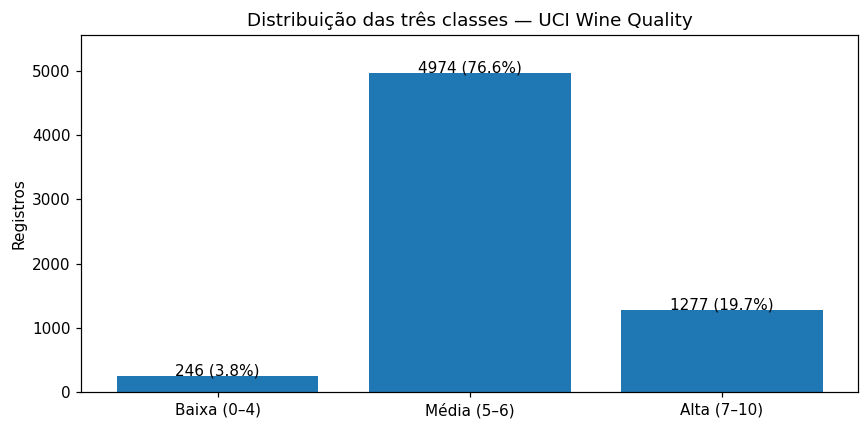

Classes: {0: 246, 1: 4974, 2: 1277}


In [ ]:
# Há observações com medições repetidas na base UCI: vamos agrupá-las na divisão.
print('Valores ausentes por coluna:\n', dados.isna().sum().to_string())
print('Duplicatas de linha inteira:', int(dados.duplicated().sum()))
print('Duplicatas de entrada (independentemente da classe):',
      int(dados.duplicated(subset=[c for c in dados.columns if c != 'quality']).sum()))
display(dados.describe().T.round(3))

def categorizar(notas):
    notas = np.asarray(notas)
    return np.select([notas <= 4, notas <= 6], [0, 1], default=2).astype(np.int64)

dados['classe'] = categorizar(dados['quality'])
assert (dados.loc[dados['quality'] <= 4, 'classe'] == 0).all()
assert (dados.loc[dados['quality'].between(5, 6), 'classe'] == 1).all()
assert (dados.loc[dados['quality'] >= 7, 'classe'] == 2).all()
contagens = dados['classe'].value_counts().reindex(range(3), fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(NOMES_CLASSES, contagens)
for i, n in enumerate(contagens): ax.text(i, n+10, f'{n} ({n/len(dados):.1%})', ha='center')
ax.set_ylim(0, max(contagens)*1.12)
ax.set_ylabel('Registros'); ax.set_title('Distribuição das três classes — UCI Wine Quality')
fig.tight_layout(); plt.show()
print('Classes:', contagens.to_dict())

## 4. Separação estratificada por grupos de duplicatas (sem vazamento)

In [ ]:
# Não incluímos 'quality' nem 'classe' nas entradas: seriam vazamento direto do alvo.
entradas = [col for col in dados.columns if col not in ('quality', 'classe')]
X_df = dados[entradas].copy()
y = dados['classe'].to_numpy(dtype=np.int64)
# Linhas com a mesma combinação de medidas pertencem ao mesmo grupo.
# dropna=False e factorize garantem que observações idênticas permaneçam juntas.
grupos = pd.factorize(pd.MultiIndex.from_frame(X_df), sort=False)[0]
assert len(np.unique(grupos)) <= len(grupos)
partidor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
idx_ajuste, idx_teste = next(partidor.split(X_df, y, groups=grupos))
partidor_val = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE+1)
loc_treino, loc_val = next(partidor_val.split(X_df.iloc[idx_ajuste], y[idx_ajuste], groups=grupos[idx_ajuste]))
idx_treino, idx_val = idx_ajuste[loc_treino], idx_ajuste[loc_val]
assert set(idx_treino).isdisjoint(idx_val)
assert set(idx_treino).isdisjoint(idx_teste)
assert set(idx_val).isdisjoint(idx_teste)
assert len(idx_treino)+len(idx_val)+len(idx_teste)==len(dados)
for a,b in [(idx_treino,idx_val),(idx_treino,idx_teste),(idx_val,idx_teste)]:
    assert np.intersect1d(grupos[a], grupos[b]).size==0, 'Grupos duplicados cruzaram a divisão!'
for nome, idx in [('Treino', idx_treino), ('Validação', idx_val), ('Teste', idx_teste)]:
    cc = np.bincount(y[idx], minlength=3)
    assert np.all(cc > 0), f'{nome} não contém todas as classes'
    print(f'{nome}: {len(idx)} ({len(idx)/len(dados):.1%}); baixa/média/alta:',cc.tolist())
# Cópias isoladas por conjunto.
X_treino_df, X_val_df, X_teste_df = (X_df.iloc[ix].copy() for ix in [idx_treino, idx_val, idx_teste])
y_treino, y_val, y_teste = y[idx_treino], y[idx_val], y[idx_teste]
print('Amostras duplicadas agrupadas:', len(dados)-len(np.unique(grupos)))

Treino: 4171 (64.2%); baixa/média/alta: [147, 3198, 826]
Validação: 1036 (15.9%); baixa/média/alta: [47, 784, 205]
Teste: 1290 (19.9%); baixa/média/alta: [52, 992, 246]
Amostras duplicadas agrupadas: 1177


## 5. Redundância, valores ausentes e padronização — somente no treino
Atributos com correlação absoluta acima de 0,95 serão considerados potencialmente redundantes; entre pares altamente correlacionados, um é removido deterministamente. A correlação é calculada **somente no treinamento**. Essa regra não pressupõe que toda variável correlacionada seja inútil; é uma política explícita e conservadora de pré-processamento.

Pares altamente correlacionados (>0,95): nenhum
Atributos removidos: nenhum (não há redundância extrema)
Atributos utilizados: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'tipo_branco']


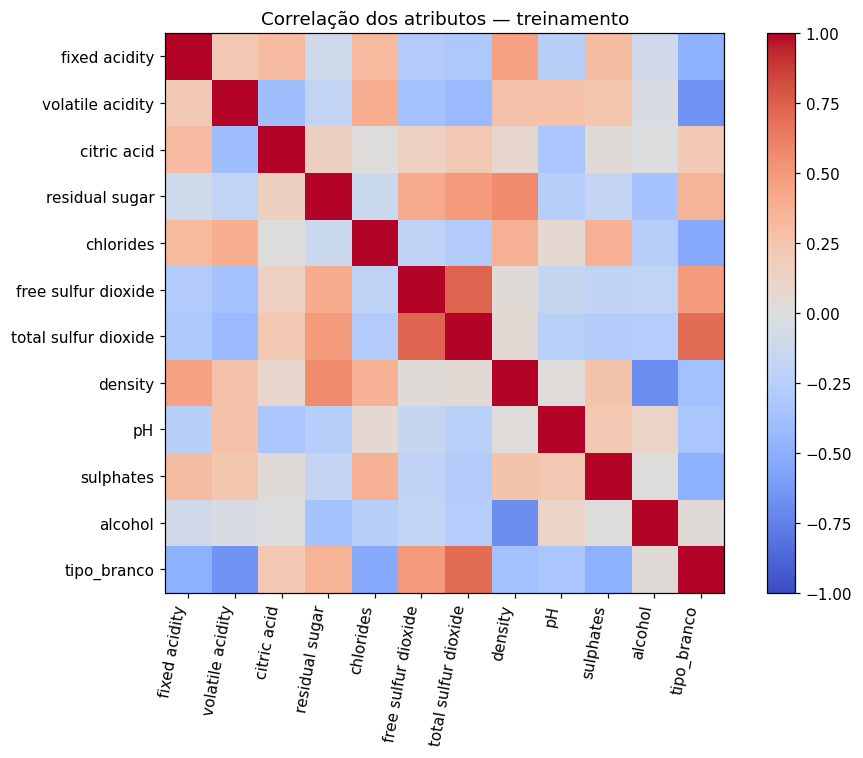

Entradas após pré-processamento: 12


In [ ]:
# Mapeamento imputação/escala ajustado em treino, reaplicado nos outros conjuntos.
imputador = SimpleImputer(strategy='median')
Xtr_imp = pd.DataFrame(imputador.fit_transform(X_treino_df), columns=entradas, index=X_treino_df.index)
Xva_imp = pd.DataFrame(imputador.transform(X_val_df), columns=entradas, index=X_val_df.index)
Xte_imp = pd.DataFrame(imputador.transform(X_teste_df), columns=entradas, index=X_teste_df.index)

corr_treino = Xtr_imp.corr(numeric_only=True).fillna(0)
tri_sup = corr_treino.abs().where(np.triu(np.ones(corr_treino.shape), k=1).astype(bool))
pares = [(corr_treino.columns[i], corr_treino.columns[j], float(tri_sup.iloc[i,j]))
         for i,j in zip(*np.where(tri_sup.to_numpy() > 0.95))]
remover = [c for c in tri_sup.columns if (tri_sup[c] > 0.95).any()]
colunas_uso = [c for c in entradas if c not in remover]
assert colunas_uso and 'quality' not in colunas_uso and 'classe' not in colunas_uso
print('Pares altamente correlacionados (>0,95):', pares or 'nenhum')
print('Atributos removidos:', remover or 'nenhum (não há redundância extrema)')
print('Atributos utilizados:', colunas_uso)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_treino, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(entradas)), entradas, rotation=80, ha='right')
ax.set_yticks(range(len(entradas)), entradas)
ax.set_title('Correlação dos atributos — treinamento')
fig.colorbar(im, ax=ax, fraction=.046)
fig.tight_layout(); plt.show()

escalonador = StandardScaler()
X_treino = escalonador.fit_transform(Xtr_imp[colunas_uso]).astype(np.float32)
X_val = escalonador.transform(Xva_imp[colunas_uso]).astype(np.float32)
X_teste = escalonador.transform(Xte_imp[colunas_uso]).astype(np.float32)
assert np.isfinite(X_treino).all() and np.isfinite(X_val).all() and np.isfinite(X_teste).all()
print('Entradas após pré-processamento:', X_treino.shape[1])

## 6. Estratégia para desbalanceamento e arquitetura MLP

In [ ]:
pesos = compute_class_weight(class_weight='balanced', classes=np.arange(3), y=y_treino)
print('Distribuição de treino:', np.bincount(y_treino, minlength=3).tolist())
print('Pesos inversamente proporcionais à frequência:', np.round(pesos, 4))
print('Estratégia: cross-entropy ponderada; sem SMOTE, por preservar dados reais.')

class WineMLP(nn.Module):
    def __init__(self, n_entradas):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(n_entradas, 64), nn.ReLU(), nn.Dropout(0.25),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.15),
            nn.Linear(32, 3)
        )
    def forward(self, x): return self.rede(x)

modelo = WineMLP(X_treino.shape[1]).to(DISPOSITIVO)
print(modelo)
print('Parâmetros treináveis:', sum(p.numel() for p in modelo.parameters()))
with torch.no_grad():
    assert modelo(torch.zeros(4, X_treino.shape[1], device=DISPOSITIVO)).shape == (4,3)
# Saídas são logits. Não usar softmax antes da CrossEntropyLoss.
criterio = nn.CrossEntropyLoss(weight=torch.tensor(pesos, dtype=torch.float32, device=DISPOSITIVO))
otimizador = torch.optim.Adam(modelo.parameters(), lr=0.001, weight_decay=1e-4)
conjunto_treino = TensorDataset(torch.from_numpy(X_treino), torch.from_numpy(y_treino))
loader_treino = DataLoader(conjunto_treino, batch_size=64, shuffle=True,
                          generator=torch.Generator().manual_seed(SEMENTE))
Xt_val_t = torch.tensor(X_val, dtype=torch.float32, device=DISPOSITIVO)
yt_val_t = torch.tensor(y_val, dtype=torch.long, device=DISPOSITIVO)

Distribuição de treino: [147, 3198, 826]
Pesos inversamente proporcionais à frequência: [9.458  0.4348 1.6832]
Estratégia: cross-entropy ponderada; sem SMOTE, por preservar dados reais.
WineMLP(
  (rede): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.25, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.15, inplace=False)
    (6): Linear(in_features=32, out_features=3, bias=True)
  )
)
Parâmetros treináveis: 3011


## 7. Treinamento e seleção por F1-macro na validação
No treinamento, usa-se cross-entropy ponderada para compensar o desequilíbrio. O melhor modelo é escolhido pela **F1-macro de validação**, que dá a mesma importância às três classes. Em caso de empate, a perda de validação desempata. As curvas indicam a perda no **modo avaliação** com os mesmos pesos ao fim de cada época.

Época 001: CE treino 0.9667, CE val 1.0163, F1-macro val 0.389
Época 010: CE treino 0.7078, CE val 0.8892, F1-macro val 0.507
Época 020: CE treino 0.6469, CE val 0.7973, F1-macro val 0.494
Época 030: CE treino 0.6206, CE val 0.8113, F1-macro val 0.513
Época 040: CE treino 0.5916, CE val 0.8122, F1-macro val 0.491
Época 050: CE treino 0.5707, CE val 0.8407, F1-macro val 0.514
Época 060: CE treino 0.5536, CE val 0.8433, F1-macro val 0.507
Época 070: CE treino 0.5359, CE val 0.8461, F1-macro val 0.514
Parada antecipada.
Épocas executadas: 78 | Melhor época: 48 | F1-macro val: 0.5428


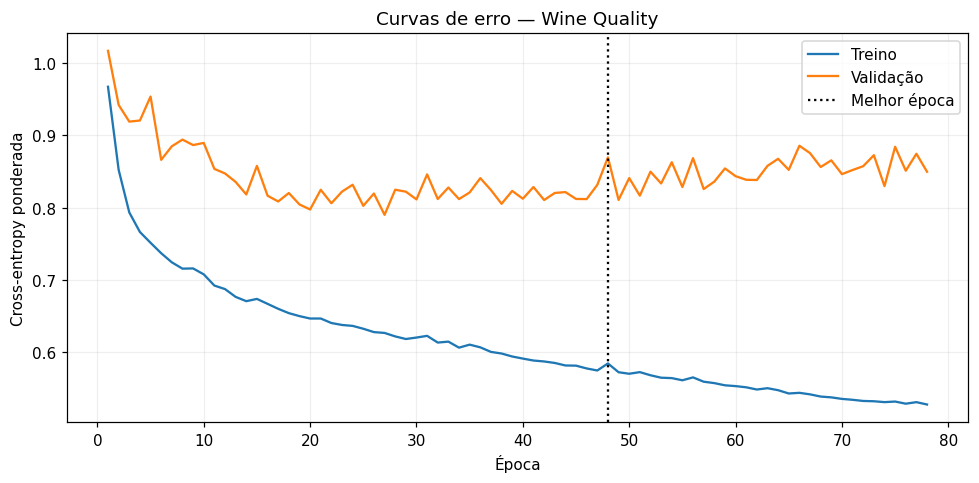

In [ ]:
MAX_EPOCAS, PACIENCIA = 250, 30
melhor_f1, menor_perda_desempate = -1., float('inf')
melhor_epoca, melhor_estado, sem_melhora = 0, None, 0
historico = []

def avaliar_particao(Xnp, ynp):
    modelo.eval()
    with torch.inference_mode():
        logits = modelo(torch.tensor(Xnp, dtype=torch.float32, device=DISPOSITIVO))
        loss = criterio(logits, torch.tensor(ynp, dtype=torch.long, device=DISPOSITIVO)).item()
        pred = logits.argmax(1).cpu().numpy()
    f1 = precision_recall_fscore_support(ynp, pred, average='macro', zero_division=0)[2]
    return float(loss), float(f1)

for epoca in range(1, MAX_EPOCAS+1):
    modelo.train()
    for xb, yb in loader_treino:
        xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
        otimizador.zero_grad(set_to_none=True)
        erro = criterio(modelo(xb), yb)
        erro.backward()
        otimizador.step()
    perda_treino, f1_treino = avaliar_particao(X_treino, y_treino)
    perda_val, f1_val = avaliar_particao(X_val, y_val)
    historico.append({'epoca':epoca, 'perda_treino':perda_treino, 'perda_val':perda_val,
                      'f1_treino':f1_treino, 'f1_val':f1_val})
    assert np.isfinite(perda_treino) and np.isfinite(perda_val)
    melhorou = f1_val > melhor_f1 + 1e-5 or (abs(f1_val - melhor_f1) <= 1e-5 and perda_val < menor_perda_desempate - 1e-5)
    if melhorou:
        melhor_f1, menor_perda_desempate = f1_val, perda_val
        melhor_estado = {k:v.detach().cpu().clone() for k,v in modelo.state_dict().items()}
        melhor_epoca, sem_melhora = epoca, 0
    else:
        sem_melhora += 1
    if epoca == 1 or epoca % 10 == 0:
        print(f'Época {epoca:03d}: CE treino {perda_treino:.4f}, CE val {perda_val:.4f}, F1-macro val {f1_val:.3f}')
    if sem_melhora >= PACIENCIA:
        print('Parada antecipada.');break
assert melhor_estado is not None
modelo.load_state_dict(melhor_estado)
modelo.eval()
print('Épocas executadas:',len(historico),'| Melhor época:',melhor_epoca,'| F1-macro val:',round(melhor_f1,4))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot([x['epoca'] for x in historico], [x['perda_treino'] for x in historico], label='Treino')
ax.plot([x['epoca'] for x in historico], [x['perda_val'] for x in historico], label='Validação')
ax.axvline(melhor_epoca, color='black', ls=':',label='Melhor época')
ax.set(xlabel='Época',ylabel='Cross-entropy ponderada',title='Curvas de erro — Wine Quality')
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(SAIDA/'curvas_treinamento_validacao.png',dpi=160)
plt.show()
pd.DataFrame(historico).to_csv(SAIDA/'historico.csv',index=False)

## 8. Teste final: accuracy, precision, recall, F1-score e matriz de confusão

ACURÁCIA NO TESTE: 60.93%
Precision macro: 0.4864 | Recall macro: 0.6208 | F1-score macro: 0.4919
Precision ponderada: 0.7700 | Recall ponderado: 0.6093 | F1 ponderado: 0.6426
Baseline (sempre classe majoritária de treino): 76.90%

Relatório por classe:
              precision    recall  f1-score   support

 Baixa (0–4)       0.18      0.48      0.26        52
 Média (5–6)       0.90      0.56      0.69       992
 Alta (7–10)       0.38      0.82      0.52       246

    accuracy                           0.61      1290
   macro avg       0.49      0.62      0.49      1290
weighted avg       0.77      0.61      0.64      1290



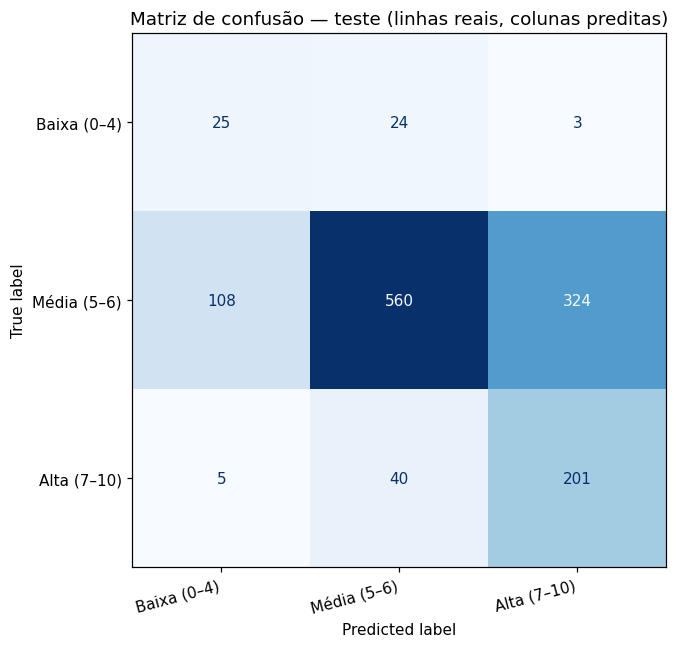

Arquivos gerados na pasta: /content/resultados_wine_quality


In [ ]:
# Uma única avaliação final: o conjunto de teste não foi usado para escolher a melhor época.
with torch.inference_mode():
    logits = modelo(torch.tensor(X_teste, dtype=torch.float32, device=DISPOSITIVO))
    previsoes = logits.argmax(1).cpu().numpy()
    probabilidades = logits.softmax(1).cpu().numpy()
assert len(previsoes) == len(y_teste) and np.allclose(probabilidades.sum(axis=1), 1, atol=1e-5)
acuracia = accuracy_score(y_teste, previsoes)
prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(y_teste,previsoes,average='macro',zero_division=0)
prec_pond, rec_pond, f1_pond, _ = precision_recall_fscore_support(y_teste,previsoes,average='weighted',zero_division=0)
print('ACURÁCIA NO TESTE:', f'{acuracia:.2%}')
print('Precision macro:',f'{prec_macro:.4f}','| Recall macro:',f'{rec_macro:.4f}','| F1-score macro:',f'{f1_macro:.4f}')
print('Precision ponderada:',f'{prec_pond:.4f}','| Recall ponderado:',f'{rec_pond:.4f}','| F1 ponderado:',f'{f1_pond:.4f}')
print('Baseline (sempre classe majoritária de treino):',f'{np.mean(y_teste == np.bincount(y_treino).argmax()):.2%}')
relatorio = classification_report(y_teste,previsoes, labels=[0,1,2], target_names=NOMES_CLASSES,zero_division=0)
print('\nRelatório por classe:\n'+relatorio)
matriz = confusion_matrix(y_teste,previsoes,labels=[0,1,2])
assert matriz.shape==(3,3) and matriz.sum()==len(y_teste)
assert np.isclose(np.trace(matriz)/matriz.sum(),acuracia)
fig,ax=plt.subplots(figsize=(7.4,6))
ConfusionMatrixDisplay(matriz,display_labels=NOMES_CLASSES).plot(ax=ax,cmap='Blues',values_format='d',colorbar=False)
ax.set_title('Matriz de confusão — teste (linhas reais, colunas preditas)')
plt.setp(ax.get_xticklabels(),rotation=15,ha='right')
fig.tight_layout();fig.savefig(SAIDA/'matriz_confusao.png',dpi=160)
plt.show()
(SAIDA/'resultados_teste.txt').write_text(
    f'Wine Quality UCI — Teste\nAmostras: {len(y_teste)}\n'
    f'Accuracy: {acuracia:.6f}\nPrecision macro: {prec_macro:.6f}\n'
    f'Recall macro: {rec_macro:.6f}\nF1-score macro: {f1_macro:.6f}\n\n'+relatorio,
    encoding='utf-8')
pd.DataFrame(matriz,index=NOMES_CLASSES,columns=NOMES_CLASSES).to_csv(SAIDA/'matriz_confusao.csv')
print('Arquivos gerados na pasta:',SAIDA.resolve())

## 9. Interpretação e limitações
A base é desbalanceada, pois a categoria média costuma predominar. Por isso, **accuracy isolada não basta**: examine o `classification_report`, especialmente recall/F1 das classes baixa e alta. A deduplicação por agrupamento impede que medições de entrada idênticas atravessem treino, validação e teste, mas **não elimina dependências não registradas** entre vinhos de mesma origem. As métricas só se tornam resultados de entrega após **executar este notebook com os CSVs oficiais**. A matriz, as curvas e os números acima são produzidos a partir do treinamento real quando o notebook é executado.

## 10. Síntese automática dos resultados

Esta conclusão usa **os valores calculados na execução**, sem atribuir desempenho à rede antes de medir o conjunto de teste.

In [ ]:
# Interpretação baseada nos resultados reais da execução, sem valores pré-definidos.
metricas_classes = precision_recall_fscore_support(y_teste, previsoes, labels=[0,1,2], zero_division=0)
f1_por_classe = metricas_classes[2]
classe_dificil = int(np.argmin(f1_por_classe))
melhoria_baseline = acuracia - np.mean(y_teste == np.bincount(y_treino).argmax())
print(f"Síntese: acurácia={acuracia:.2%}, F1-macro={f1_macro:.3f}, ")
print(f"classe com menor F1: {NOMES_CLASSES[classe_dificil]} (F1={f1_por_classe[classe_dificil]:.3f}).")
print(f"Diferença de acurácia em relação ao baseline majoritário: {melhoria_baseline:+.2%}.")
print('Consulte a matriz para analisar quais classes se confundem e não use somente accuracy para concluir.')

Síntese: acurácia=60.93%, F1-macro=0.492, 
classe com menor F1: Baixa (0–4) (F1=0.263).
Diferença de acurácia em relação ao baseline majoritário: -15.97%.
Consulte a matriz para analisar quais classes se confundem e não use somente accuracy para concluir.
